# Fixing the validation-to-test gap (Normal vs Fuzzers, DoS vs Exploits)

**What your ensemble results show**
- On validation the models had about 4% false alarms. On the official testing set the binary ensemble flags **10,935 of 37,000 normal flows (29.6%)** as attacks.
- 28% of normal flows are labelled Fuzzers and 33% of DoS flows are labelled Exploits.
- The same models, the same features: only the data changed. That is a **train-to-test shift**, not just two confused class pairs.

**Likely causes (this notebook checks the first one and works around all three)**
1. **The test flows are not distributed like the training flows** (a different mix and different kinds of normal traffic).
2. **Validation was too easy**: it comes from the same partition as training and contains near-copies of training flows (KNN scored as well as the best models). Thresholds and calibration tuned on it are too aggressive for new flows.
3. **Class weights push predictions toward attack classes**, which hurts Normal when the test set has proportionally more Normal flows (45% vs 32%).

**What this notebook does**
- **Diagnosis, adversarial validation:** can a classifier tell training rows from test rows? If yes, the shift is real, and it shows which features differ.
- **Fix A, importance weighting (uses test features, never test labels):** training rows that look like the test set count more. Variants with softer class weights are compared, and the variant is chosen on an importance-weighted validation set, not on the test set.
- **Fix B, target calibration split (uses half of the test labels):** the official testing set is split in two. One half is added to the training data (and used to reset the alert threshold), and the results are reported on the other half only. This is what a real deployment would do with a small labelled sample from its own network. **Report it separately and say clearly that it uses part of the testing partition.**

Needs `processed/unsw_nb15_processed.npz`, `processed/unsw_nb15_test.npz` (from `prepare_test_set.ipynb`) and `processed/meta.json`. Install once if needed: `pip install lightgbm`.

## 1. Imports and config

In [1]:
import json
import time
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict

PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

LGBM = dict(n_estimators=800, learning_rate=0.08, num_leaves=63, subsample=0.8, subsample_freq=1,
            colsample_bytree=0.8, reg_lambda=1.0, min_child_samples=20, n_jobs=-1, random_state=SEED, verbose=-1)
EARLY_STOPPING = 30
WEIGHT_CLIP = (0.1, 10.0)   # importance weights are clipped to this range so a few rows cannot dominate
TARGET_UPWEIGHT = 3.0       # Fix B: how much more each labelled test row counts than a training row
TARGET_FPR = 0.05           # Fix B: false alarm rate allowed when the alert threshold is reset

## 2. Load the data

In [2]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
test = np.load(proc / "unsw_nb15_test.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
X_test, yb_test, ym_test = test["X_test"].astype("float32"), test["y_bin_test"].astype(int), test["y_multi_test"].astype(int)

feature_names, class_names = meta["feature_names"], meta["class_names"]
K = len(class_names)
cw_multi = np.array([{int(k): v for k, v in meta["class_weight_multi"].items()}[i] for i in range(K)])
cw_bin = np.array([{int(k): v for k, v in meta["class_weight_binary"].items()}[i] for i in (0, 1)])
cls = {n: i for i, n in enumerate(class_names)}

print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")
share = pd.DataFrame({
    "train %": 100 * np.bincount(ym_train, minlength=K) / len(ym_train),
    "validation %": 100 * np.bincount(ym_val, minlength=K) / len(ym_val),
    "test %": 100 * np.bincount(ym_test, minlength=K) / len(ym_test)}, index=class_names)
display(share.round(1))

train 140,272   validation 35,069   test 82,332


,train %,validation %,test %
Normal,31.9,31.9,44.9
DoS,7.0,7.0,5.0
Reconnaissance,6.0,6.0,4.2
Fuzzers,10.4,10.4,7.4
Exploits,19.0,19.0,13.5
Generic,22.8,22.8,22.9
Other,2.9,2.9,2.0


## 3. Helpers

`multi_summary` reports the numbers that matter for your two problems: how many normal flows are recognised, how precise Fuzzers is, and how many DoS flows are recovered.

In [3]:
def multi_summary(y, pred):
    cm = confusion_matrix(y, pred, labels=list(range(K)))
    row = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    out = {"accuracy": accuracy_score(y, pred), "macro F1": f1_score(y, pred, average="macro"), "Normal recall": row[0, 0]}
    if "Fuzzers" in cls:
        j = cls["Fuzzers"]
        out["Fuzzers precision"] = cm[j, j] / max(cm[:, j].sum(), 1)
        out["Normal->Fuzzers"] = row[0, j]
    if "DoS" in cls and "Exploits" in cls:
        out["DoS recall"] = row[cls["DoS"], cls["DoS"]]
        out["DoS->Exploits"] = row[cls["DoS"], cls["Exploits"]]
    return out


def bin_summary(y, score, thr=0.5):
    pred = (score >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"accuracy": (tp + tn) / len(y), "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
            "f1": 2 * tp / max(2 * tp + fp + fn, 1), "false_pos_rate": fp / max(fp + tn, 1),
            "roc_auc": roc_auc_score(y, score)}


def fit_lgbm(X, y, w, objective, X_va=None, y_va=None, w_va=None, n_estimators=None):
    """LightGBM with per-row weights. Early stopping on the validation set unless n_estimators is fixed."""
    params = dict(LGBM)
    kw = {"sample_weight": w}
    if n_estimators is not None:
        params["n_estimators"] = int(n_estimators)
    else:
        kw["eval_set"] = [(X_va, y_va)]
        if w_va is not None:
            kw["eval_sample_weight"] = [w_va]
        kw["callbacks"] = [lgb.early_stopping(EARLY_STOPPING, verbose=False)]
    m = lgb.LGBMClassifier(objective=objective, **params).fit(X, y, **kw)
    m.n_used_ = int(m.best_iteration_ or params["n_estimators"])
    return m

## 4. Diagnosis: adversarial validation

A classifier is trained to tell **training rows (label 0) from test rows (label 1)**, using only the features. Its cross-validated AUC measures the shift:
- about **0.5**: the two sets look alike, so the gap is not caused by different feature distributions
- **0.6 to 0.8**: moderate shift
- **above 0.8**: strong shift

Rows that appear in both sets can lower the AUC, so a high value is a reliable sign of shift.

In [4]:
X_all = np.vstack([X_train, X_test])
y_dom = np.r_[np.zeros(len(X_train), dtype=int), np.ones(len(X_test), dtype=int)]

adv = lgb.LGBMClassifier(objective="binary", n_estimators=200, learning_rate=0.1, num_leaves=31,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=-1, random_state=SEED, verbose=-1)
t0 = time.time()
oof = cross_val_predict(adv, X_all, y_dom, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
adv_auc = roc_auc_score(y_dom, oof)
print(f"adversarial AUC (train rows vs test rows): {adv_auc:.3f}   ({time.time() - t0:.0f}s)")
print("verdict:", "strong shift" if adv_auc > 0.8 else "moderate shift" if adv_auc > 0.6 else "little feature shift")

adv.fit(X_all, y_dom)
imp = pd.Series(adv.booster_.feature_importance("gain"), index=feature_names).sort_values(ascending=False)
display((imp / imp.sum()).head(10).round(3).to_frame("share of the shift (gain)"))

adversarial AUC (train rows vs test rows): 0.881   (6s)
verdict: strong shift


,share of the shift (gain)
ct_dst_sport_ltm,0.116
ct_srv_src,0.110
ct_dst_src_ltm,0.104
sbytes,0.094
dbytes,0.069
ct_src_ltm,0.069
smean,0.061
ct_srv_dst,0.058
dmean,0.057
ct_dst_ltm,0.045


## 5. Importance weights

For every training row, `weight = P(test | x) / P(train | x)` (corrected for the different set sizes). Rows that look like test flows get a weight above 1, rows unlike any test flow get a weight below 1. Weights are cut to `WEIGHT_CLIP` and scaled to an average of 1. The validation rows get weights too (from a classifier that never saw them), so validation can be made to **mimic the test distribution without using any test labels**.

In [5]:
def density_ratio(p, n_num, n_den):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return (p / (1 - p)) * (n_num / n_den)          # = p_test(x) / p_train(x)


iw_train = density_ratio(oof[:len(X_train)], len(X_train), len(X_test))
iw_val = density_ratio(adv.predict_proba(X_val)[:, 1], len(X_train), len(X_test))
iw_train = np.clip(iw_train, *WEIGHT_CLIP); iw_val = np.clip(iw_val, *WEIGHT_CLIP)
iw_train /= iw_train.mean(); iw_val /= iw_val.mean()

ess = iw_train.sum() ** 2 / (iw_train ** 2).sum()
print(f"effective training rows after weighting: {ess:,.0f} of {len(X_train):,}")
display(pd.DataFrame({"mean weight (train)": pd.Series(iw_train).groupby(ym_train).mean().values,
                      "rows": np.bincount(ym_train, minlength=K)}, index=class_names).round(2))

effective training rows after weighting: 57,785 of 140,272


,mean weight (train),rows
Normal,1.16,44800
DoS,0.64,9811
Reconnaissance,1.06,8392
Fuzzers,1.53,14547
Exploits,1.00,26715
Generic,0.56,32000
Other,1.56,4007


## 6. Fix A: retrain with importance weights (multiclass)

Four variants are trained. **Which one is used is decided on the importance-weighted validation set, not on the test set**, so no test labels influence the choice. The test numbers are printed for all variants so you can see the effect.

In [6]:
VARIANTS = {   # name: (use importance weights, power applied to the balanced class weights)
    "baseline (balanced class weights)":  (False, 1.0),
    "softer class weights":               (False, 0.5),
    "importance weights":                 (True, 1.0),
    "importance + softer class weights":  (True, 0.5),
}


def row_weights(y, cw, iw, use_iw, power):
    w = cw[y] ** power
    if use_iw:
        w = w * iw
    return w / w.mean()


models, rows = {}, []
for name, (use_iw, power) in VARIANTS.items():
    t0 = time.time()
    w_tr = row_weights(ym_train, cw_multi, iw_train, use_iw, power)
    m = fit_lgbm(X_train, ym_train, w_tr, "multiclass", X_val, ym_val, iw_val if use_iw else None)
    pv, pt = m.predict(X_val), m.predict(X_test)
    models[name] = m
    rows.append({"variant": name, "trees": m.n_used_,
                 "IW-validation macro F1": f1_score(ym_val, pv, average="macro", sample_weight=iw_val),
                 **{f"test {k}": v for k, v in multi_summary(ym_test, pt).items()}})
    print(f"{name:38s} {time.time() - t0:5.0f}s")

res = pd.DataFrame(rows)
chosen = res.loc[res["IW-validation macro F1"].idxmax(), "variant"]
res.insert(1, "chosen", np.where(res["variant"] == chosen, "<<<", ""))
display(res.round(4))
print("chosen on the importance-weighted VALIDATION set:", chosen)

c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


baseline (balanced class weights)          3s


c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


softer class weights                       3s


c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


importance weights                         6s


c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


importance + softer class weights          6s


,variant,chosen,trees,IW-validation macro F1,test accuracy,test macro F1,test Normal recall,test Fuzzers precision,test Normal->Fuzzers,test DoS recall,test DoS->Exploits
0,baseline (balanced class weights),,45,0.7563,0.6914,0.6063,0.5929,0.2565,0.3250,0.4527,0.1453
1,softer class weights,,45,0.7591,0.7209,0.6130,0.6525,0.2749,0.2817,0.4180,0.2839
2,importance weights,,96,0.7587,0.6980,0.6010,0.6210,0.2441,0.3105,0.3942,0.1531
3,importance + softer class weights,<<<,106,0.7680,0.7307,0.6113,0.6911,0.2626,0.2547,0.4057,0.2580


chosen on the importance-weighted VALIDATION set: importance + softer class weights


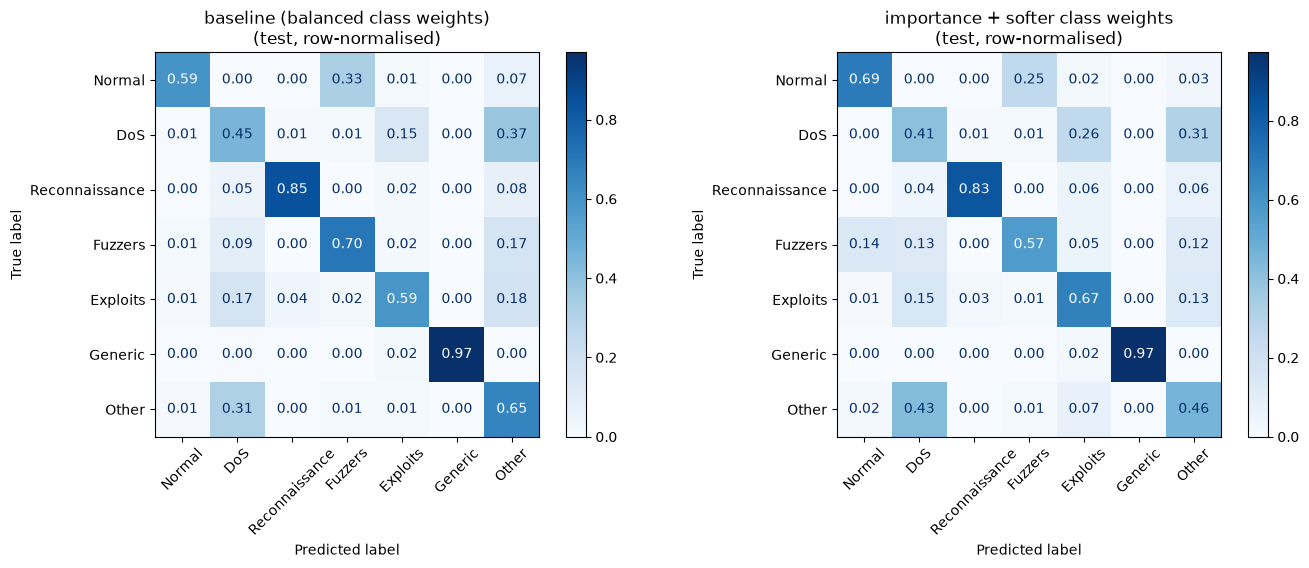

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name in zip(axes, ["baseline (balanced class weights)", chosen]):
    ConfusionMatrixDisplay.from_predictions(ym_test, models[name].predict(X_test), labels=list(range(K)),
                                            display_labels=class_names, normalize="true", cmap="Blues",
                                            ax=ax, values_format=".2f", xticks_rotation=45)
    ax.set_title(f"{name}\n(test, row-normalised)")
plt.tight_layout(); plt.show()

## 7. Fix A for the binary detector (normal vs attack)

This is the model behind your false alarm rate. The binary model uses the same weighting variant that was chosen above.

In [8]:
use_iw, power = VARIANTS[chosen]
bin_base = fit_lgbm(X_train, yb_train, row_weights(yb_train, cw_bin, iw_train, False, 1.0), "binary", X_val, yb_val)
bin_fix = fit_lgbm(X_train, yb_train, row_weights(yb_train, cw_bin, iw_train, use_iw, power), "binary",
                   X_val, yb_val, iw_val if use_iw else None)

score_base, score_fix = bin_base.predict_proba(X_test)[:, 1], bin_fix.predict_proba(X_test)[:, 1]
display(pd.DataFrame({"baseline binary": bin_summary(yb_test, score_base),
                      "importance-weighted binary": bin_summary(yb_test, score_fix)}).T.round(4))

c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,accuracy,precision,recall,f1,false_pos_rate,roc_auc
baseline binary,0.8937,0.8618,0.9611,0.9087,0.1889,0.9798
importance-weighted binary,0.8823,0.8421,0.9677,0.9006,0.2223,0.9795


## 8. Fix B: target calibration split (uses half of the test labels)

The official testing set is split into **half A** and **half B** (identical rows always stay together, and classes stay balanced).
- Half A is added to the training data (counted `TARGET_UPWEIGHT` times) and is used to reset the alert threshold.
- **All results below are measured on half B only**, with the baseline and Fix A models scored on the same rows, so the comparison is fair.

Disclose this in the report: it uses part of the testing partition, as a deployment would use a small labelled sample from its own network.

**Caution:** the testing set contains near-copies of its own flows, so half B can hold near-copies of half A rows. Part of the Fix B gain is therefore memorisation, and it should be reported as an optimistic estimate of what adaptation can achieve.

In [9]:
hash_rows = pd.util.hash_pandas_object(pd.DataFrame(np.round(X_test, 4)), index=False).to_numpy()
groups = pd.factorize(hash_rows)[0]
idx_a, idx_b = next(StratifiedGroupKFold(2, shuffle=True, random_state=SEED).split(X_test, ym_test, groups))
print(f"half A: {len(idx_a):,} rows   half B: {len(idx_b):,} rows")

# multiclass: train + half A
w_a = (cw_multi[ym_test[idx_a]] ** power) * TARGET_UPWEIGHT
w_comb = np.r_[row_weights(ym_train, cw_multi, iw_train, use_iw, power) * 1.0, w_a]
w_comb = w_comb / w_comb.mean()
X_comb, y_comb = np.vstack([X_train, X_test[idx_a]]), np.r_[ym_train, ym_test[idx_a]]
adapted = fit_lgbm(X_comb, y_comb, w_comb, "multiclass", n_estimators=models[chosen].n_used_)

on_b = lambda m: multi_summary(ym_test[idx_b], m.predict(X_test[idx_b]))
table_b = pd.DataFrame({"baseline": on_b(models["baseline (balanced class weights)"]),
                        "Fix A (importance weights)": on_b(models[chosen]),
                        "Fix B (train + half A)": on_b(adapted)}).T
display(table_b.round(4))

half A: 41,166 rows   half B: 41,166 rows


,accuracy,macro F1,Normal recall,Fuzzers precision,Normal->Fuzzers,DoS recall,DoS->Exploits
baseline,0.6949,0.6072,0.5999,0.2615,0.3159,0.4755,0.1477
Fix A (importance weights),0.7332,0.6089,0.6977,0.2674,0.2468,0.4173,0.2657
Fix B (train + half A),0.8200,0.6888,0.8474,0.4732,0.1271,0.4217,0.2148


In [10]:
# binary: alert threshold reset on half A so that false alarms stay at TARGET_FPR, then measured on half B
fix_a_scores = bin_fix.predict_proba(X_test)[:, 1]
fpr_a, tpr_a, thr_a = roc_curve(yb_test[idx_a], fix_a_scores[idx_a])
ok = np.flatnonzero(fpr_a <= TARGET_FPR)
thr_target = float(thr_a[ok[-1]])
print(f"threshold reset on half A (false alarms <= {TARGET_FPR:.0%}): {thr_target:.3f}")

b = idx_b
display(pd.DataFrame({
    "baseline binary, threshold 0.5": bin_summary(yb_test[b], score_base[b], 0.5),
    "Fix A binary, threshold 0.5": bin_summary(yb_test[b], fix_a_scores[b], 0.5),
    "Fix A binary, threshold from half A": bin_summary(yb_test[b], fix_a_scores[b], thr_target)}).T.round(4))

threshold reset on half A (false alarms <= 5%): 0.916


,accuracy,precision,recall,f1,false_pos_rate,roc_auc
"baseline binary, threshold 0.5",0.8956,0.8647,0.9608,0.9102,0.1842,0.9799
"Fix A binary, threshold 0.5",0.8851,0.8459,0.9676,0.9027,0.2159,0.9798
"Fix A binary, threshold from half A",0.9219,0.9573,0.8982,0.9268,0.0491,0.9798


## 9. Save

`lgbm_iw_multiclass.joblib` and `lgbm_iw_binary.joblib` are the **Fix A** models (they never saw test labels), so they can join the ensemble and be evaluated on the full testing set. The Fix B model saw half of the test labels and is **not** saved for the ensemble.

In [11]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)
joblib.dump(models[chosen], mdir / "lgbm_iw_multiclass.joblib", compress=3)
joblib.dump(bin_fix, mdir / "lgbm_iw_binary.joblib", compress=3)
res.to_csv(mdir / "domain_shift_variants_test.csv", index=False)
table_b.to_csv(mdir / "domain_shift_halfB_comparison.csv")
print("saved lgbm_iw_multiclass.joblib, lgbm_iw_binary.joblib and the comparison tables to", mdir)

saved lgbm_iw_multiclass.joblib, lgbm_iw_binary.joblib and the comparison tables to models


## 10. Using the result

**Add the Fix A model to the ensemble** (two small edits in `ensemble_decision.ipynb`, then rerun it):
1. In the config cell, add `"lgbm_iw"` to `CANDIDATES`.
2. In `load_predictor`, change `if tag in ("rf", "extratrees", "lgbm"):` to `if tag in ("rf", "extratrees", "lgbm", "lgbm_iw"):`.

The ensemble ranks members by plain validation score, which is exactly what misled it before. If `lgbm_iw` is not picked, add it to the member lists by hand after the ranking cell.

**For the report**
- Quote the validation-to-test gap and the adversarial AUC as the diagnosis.
- Report Fix A as the label-free result and Fix B as the adapted result on half B, with that disclosure.
- Importance weighting only corrects a change in how flows are distributed. It cannot fix flows that carry a different label in the test set (for example test Normal flows that look like training Fuzzers). If Fix A changes little, that is the likely reason, and Fix B (labelled data from the target network) is the real remedy.
- If the AUC is near 0.5, the gap is mostly validation being too easy. Then the test numbers are the honest ones, and the Fix B threshold reset is the practical remedy.
- DoS versus Exploits stays largely confused either way, because the TTL features are missing. Report them as one family, or log TTL from Zeek.